# COMET — GRN dictionary + ATAC-led velocity (PAIRED)

Paired scRNA + scATAC (same cells in both modalities) → per-cell GRN mixing + differentiation velocity.

**What changed vs. the unpaired version (only the matching step):**
- The dataset is now **paired**: every cell has its own ATAC profile, so the nearest-neighbor
  RNA→ATAC matching (`build_local_atac`) is **removed**. Each cell's gene activity comes from
  its *own* chromatin. Nothing else in the model changes.
- The lead is still `lead = atac_z − rna_z`, still routed through the learned GRN
  (`v = GRN · tf_lead`), still per-cell, no pseudotime, no global potential. All the math from
  the unpaired model is preserved verbatim.
- Cell types come from `obs['cell_type']` (no FACS-gate reconstruction). Pseudotime is not in
  this dataset; a Decipher-derived ordering is computed **for plot coloring / read-only
  diagnostics only** — the model never sees it.
- Gene/TF/peak name matching is case-insensitive (mouse symbols differ in casing across files).
- New final section plots the **computed lead across Decipher space** (magnitude, projected
  field, per-gene ATAC–RNA concordance, top switching TFs) — the direct test of whether the
  bad trajectories were a matching artifact.

---

## Config — set everything here

In [4]:
import os

# ── file system ───────────────────────────────────────────────────────────────
BASE     = "/home/sc5625/cll_project/decipher_atac_project/decipher-atac/paired"
RUN_TAG  = "paired_run1"                       # change per run
OUT_DIR  = f"bert_grn_out_{RUN_TAG}"
os.makedirs(OUT_DIR, exist_ok=True)

# ── input files (paired dataset) ──────────────────────────────────────────────
RNA_H5AD      = f"{BASE}/Ma-2020-RNA.h5ad"
ATAC_H5AD     = f"{BASE}/Ma-2020-ATAC.h5ad"            # SAME cells as RNA (paired)
PEAK_TF_MTX   = f"{BASE}/ma2020_peak_tf.mtx"           # (n_peaks x n_tf); rows align to ATAC var
TF_NAMES_TXT  = f"{BASE}/ma2020_tf_names.txt"          # columns of PEAK_TF_MTX
PEAK_GENE_CSV = f"{BASE}/ma2020_peak_gene.csv"         # tab-sep: peak <tab> gene
DECIPHER_DIR  = f"{BASE}/paired_decipher_outputs"      # holds the decipher embeddings .npz

# optional external comparison file (CellOracle appendix only)
CELLORACLE_A  = f"{BASE}/_decipher_models/A_learned.npy"

# ── column names / keys ───────────────────────────────────────────────────────
CELLTYPE_KEY   = "cell_type"       # obs column present in both modalities
PSEUDOTIME_KEY = None              # set to an obs column if you have one; else a proxy is built
DECIPHER_BASIS = "X_decipher"      # obsm key we populate for the scanpy marker panel

# ── model / data hyperparameters ──────────────────────────────────────────────
N_TOP_HVG   = 3000
D_ATOMS     = 4        # number of GRN dictionary atoms (archetypes ≈ terminal fates + origin)
NUM_RUNS    = 1
N_EPOCHS    = 120
PHASE1_EPOCHS = 40
BATCH_SIZE  = 512
NEIGHBOR_SPACE = "latent"                  # "decipher" | "pca" | "latent"

# GRN-mixing controls
GEO_TAU_SCALE = 0.5     # smaller -> sharper geometric targets q (less mixing)
LAMBDA_GRN    = 1.0     # weight of GRN-propagated lead inside the velocity disequilibrium

# velocity controls (unified per-cell field — NO global potential / potency prior)
# K_MOMENT is the ONLY per-dataset velocity knob: how hard the ATAC/RNA lead is denoised
# before it becomes the arrow of time. This dataset is LARGE (~32k cells), so a slightly
# larger moment than the tiny hematopoiesis set is fine; drop it if the fan-out washes out.
K_MOMENT    = 15        # kNN first-moment smoothing of BOTH modalities + the lead

# mouse skin / hair-follicle markers (Ma-2020). Only used for plot highlighting; any missing
# from the RNA var are silently skipped, so edit freely.
MARKER_GENES = ['Krt14', 'Krt15', 'Cd34', 'Lgr5', 'Sox9', 'Lef1', 'Krt1', 'Krt10', 'Mki67']

# hair lineage restriction + stratified subsampling
HAIR_LINEAGE = [
    "ahigh CD34+ bulge",
    "alow CD34+ bulge",
    "ORS",
    "TAC-1",
    "TAC-2",
    "IRS",
    "Hair Shaft-Cuticle/Cortex",
    "Medulla",
]
N_CELLS_SUBSET = 5000
RANDOM_SEED    = 0

## Imports

In [5]:
import os, glob
import numpy as np
import pandas as pd
import scipy.io
import anndata as ad
import scanpy as sc
from scipy.sparse import lil_matrix, csr_matrix, issparse
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, RandomSampler

import matplotlib.pyplot as plt

## Helper functions

In [6]:
def as_dense(x):
    return x.toarray() if issparse(x) else np.asarray(x)

def norm_name(s):
    """Case/space-insensitive key so mouse symbols match across files."""
    return str(s).strip().casefold()

def zscore_cols(A, eps=1e-8):
    """Per-gene (per-column) z-score across cells."""
    A = np.asarray(A, dtype=np.float32)
    return (A - A.mean(axis=0, keepdims=True)) / (A.std(axis=0, keepdims=True) + eps)

## Step 1: Load paired RNA + ATAC, normalize RNA, select HVGs, define universe

In [19]:
def load_decipher(decipher_dir):
    """Load z (latent) + v (2D) from an .npz in the decipher outputs dir."""
    cands = sorted(glob.glob(os.path.join(decipher_dir, "*.npz")))
    assert cands, f"No .npz found in {decipher_dir}"
    for path in cands:
        d = np.load(path, allow_pickle=True)
        keys = list(d.keys())
        z = next((d[k] for k in ('z', 'decipher_z', 'Z', 'z_latent', 'X_decipher_z') if k in keys), None)
        v = next((d[k] for k in ('v', 'decipher_v', 'V', 'z_2d', 'X_decipher') if k in keys), None)
        if z is None or v is None:                      
            arrs = [(k, d[k]) for k in keys if getattr(d[k], 'ndim', 0) == 2]
            v = v if v is not None else next((a for _, a in arrs if a.shape[1] == 2), None)
            z = z if z is not None else next((a for _, a in arrs if a.shape[1] > 2), None)
        if z is not None and v is not None:
            print(f"Loaded Decipher from {os.path.basename(path)} (keys={keys})")
            return np.asarray(z, np.float32), np.asarray(v, np.float32)
    raise KeyError(f"Could not find z/v arrays in {cands}")

# ── load both modalities (paired: identical cells, identical order) ───────────
rna_adata  = ad.read_h5ad(RNA_H5AD)
atac_adata = ad.read_h5ad(ATAC_H5AD)

# enforce the pairing explicitly; reorder ATAC to RNA if needed
assert rna_adata.n_obs == atac_adata.n_obs, "RNA/ATAC cell counts differ — not paired?"
if not (rna_adata.obs_names == atac_adata.obs_names).all():
    atac_adata = atac_adata[rna_adata.obs_names].copy()
assert (rna_adata.obs_names == atac_adata.obs_names).all(), "cell order still mismatched"
print(f"Paired cells: {rna_adata.n_obs} | RNA genes: {rna_adata.n_vars} | ATAC peaks: {atac_adata.n_vars}")

# ── restrict to hair-lineage cell types (same mask applied to both modalities) ─
mask = rna_adata.obs[CELLTYPE_KEY].isin(HAIR_LINEAGE)
rna_adata  = rna_adata[mask].copy()
atac_adata = atac_adata[mask].copy()
assert (rna_adata.obs_names == atac_adata.obs_names).all(), "cell order mismatched after lineage filter"
print(f"Hair-lineage cells: {rna_adata.n_obs}")

# =========================================================================
# NEW: Load Decipher HERE, while rna_adata still has 11,659 cells
# =========================================================================
Z_dec_full, V_dec2_full = load_decipher(DECIPHER_DIR)
assert Z_dec_full.shape[0] == rna_adata.n_obs, \
    f"Decipher array rows ({Z_dec_full.shape[0]}) != filtered cells ({rna_adata.n_obs})"

# ── stratified subsample to N_CELLS_SUBSET, proportional per cell type ────────
rng = np.random.default_rng(RANDOM_SEED)
if rna_adata.n_obs > N_CELLS_SUBSET:
    obs_df = rna_adata.obs[[CELLTYPE_KEY]].copy()
    obs_df["orig_idx"] = np.arange(rna_adata.n_obs)
    frac = N_CELLS_SUBSET / rna_adata.n_obs

    keep_idx = []
    for ct, grp in obs_df.groupby(CELLTYPE_KEY):
        n_keep = min(len(grp), max(1, int(round(len(grp) * frac))))
        chosen = rng.choice(grp["orig_idx"].values, size=n_keep, replace=False)
        keep_idx.append(chosen)
    keep_idx = np.sort(np.concatenate(keep_idx))

    # Apply the EXACT SAME mask to RNA, ATAC, and the Decipher arrays
    rna_adata  = rna_adata[keep_idx].copy()
    atac_adata = atac_adata[keep_idx].copy()
    Z_dec      = Z_dec_full[keep_idx].copy()
    V_dec2     = V_dec2_full[keep_idx].copy()
    
    assert (rna_adata.obs_names == atac_adata.obs_names).all(), "cell order mismatched after subsample"
    print(f"Subsampled to: {rna_adata.n_obs} cells")
else:
    Z_dec  = Z_dec_full
    V_dec2 = V_dec2_full

# Assign it securely to the now-subsampled rna_adata
rna_adata.obsm[DECIPHER_BASIS] = V_dec2

# ── RNA normalization (X is raw counts) ───────────────────────────────────────
print("Normalizing and log-transforming RNA counts...")
# ... [rest of your original normalization code continues here unchanged]
sc.pp.normalize_total(rna_adata, target_sum=1e4)
sc.pp.log1p(rna_adata)

sc.pp.highly_variable_genes(rna_adata, n_top_genes=N_TOP_HVG, subset=False)
hvg_genes = set(rna_adata.var_names[rna_adata.var['highly_variable']])

gene_names_all   = np.array(rna_adata.var_names.astype(str))
gene_to_idx_full = {g: i for i, g in enumerate(gene_names_all)}
# normalized-key -> canonical RNA symbol (first occurrence wins)
rna_norm_to_canon = {}
for g in gene_names_all:
    rna_norm_to_canon.setdefault(norm_name(g), g)
X_full = as_dense(rna_adata.X).astype(np.float32)

# ── context files ─────────────────────────────────────────────────────────────
peak_tf = scipy.io.mmread(PEAK_TF_MTX).tocsr()                      # (P, T_all)
motif_tf_names   = open(TF_NAMES_TXT).read().split()                # length T_all
motif_norm_to_col = {}
for i, t in enumerate(motif_tf_names):
    motif_norm_to_col.setdefault(norm_name(t), i)

peak_gene = pd.read_csv(PEAK_GENE_CSV, sep="\t")
peak_gene.columns = [c.strip().lower() for c in peak_gene.columns]  # -> 'peak','gene'
pg_gene_norm = peak_gene["gene"].astype(str).map(norm_name)
genes_in_peaks_norm = set(pg_gene_norm.unique())

# ── functional TFs = motif TFs that are present as RNA genes (canonical names) ─
A_tfs = list(dict.fromkeys(
    rna_norm_to_canon[norm_name(t)] for t in motif_tf_names if norm_name(t) in rna_norm_to_canon
))
A_tfs = np.array(A_tfs, dtype=str)

# ── target genes = (in peaks AND HVG) OR functional TF; TFs always protected ──
A_tf_set = set(A_tfs)
A_genes = np.array([
    g for g in gene_names_all
    if (norm_name(g) in genes_in_peaks_norm and g in hvg_genes) or g in A_tf_set
], dtype=str)
print(f"Target genes (A_genes): {len(A_genes)}  |  TFs (A_tfs): {len(A_tfs)}")

gene_idx = np.array([gene_to_idx_full[g] for g in A_genes], dtype=int)
tf_idx   = np.array([gene_to_idx_full[t] for t in A_tfs],   dtype=int)
X    = X_full[:, gene_idx]     # (N, G) normalized HVG expression
X_TF = X_full[:, tf_idx]       # (N, T) normalized TF expression
sub_g2i = {g: i for i, g in enumerate(A_genes)}

Paired cells: 32231 | RNA genes: 21478 | ATAC peaks: 340341
Hair-lineage cells: 11659
Loaded Decipher from decipher_embeddings.npz (keys=['v', 'z'])


/tmp/ipykernel_1996/2398175729.py:52: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for ct, grp in obs_df.groupby(CELLTYPE_KEY):


Subsampled to: 4999 cells
Normalizing and log-transforming RNA counts...
Target genes (A_genes): 2719  |  TFs (A_tfs): 788


## Step 2: Peak universe + M (gene × TF motif-accessibility mask)

In [43]:
# ── canonical peak names in ATAC-var order (peak_tf rows assumed to match ATAC var) ──
av = atac_adata.var
if {'chrom', 'chromStart', 'chromEnd'}.issubset(av.columns):
    peak_names = (av['chrom'].astype(str) + "_" +
                  av['chromStart'].astype(int).astype(str) + "_" +
                  av['chromEnd'].astype(int).astype(str)).tolist()
else:
    peak_names = list(atac_adata.var_names.astype(str))

# if the constructed names don't overlap peak_gene, fall back to raw var_names
_pg_peaks = set(peak_gene["peak"].astype(str))
if len(set(peak_names) & _pg_peaks) < 0.2 * len(_pg_peaks):
    peak_names = list(atac_adata.var_names.astype(str))
peak_to_idx = {p: i for i, p in enumerate(peak_names)}
print(f"Peaks: {len(peak_names)} | overlap with peak_gene: "
      f"{len(set(peak_names) & _pg_peaks)}/{len(_pg_peaks)}")
assert peak_tf.shape[0] == len(peak_names), \
    f"peak_tf rows ({peak_tf.shape[0]}) != n_peaks ({len(peak_names)}); check row ordering"

# ── peak × gene incidence (rows = ATAC-var order, cols = A_genes) ─────────────
P, G = len(peak_names), len(A_genes)
peak_gene_mat = lil_matrix((P, G), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = str(row["peak"]); gk = norm_name(row["gene"])
    if p in peak_to_idx and gk in rna_norm_to_canon:
        g = rna_norm_to_canon[gk]
        if g in sub_g2i:
            peak_gene_mat[peak_to_idx[p], sub_g2i[g]] = 1.0
peak_gene_mat = peak_gene_mat.tocsr()

# gene × TF mask
M_full = (peak_gene_mat.T @ peak_tf)              # (G, T_all)
M_full = (M_full > 0).astype(np.float32)
tf_col = np.array([motif_norm_to_col[norm_name(t)] for t in A_tfs], dtype=int)
M = M_full[:, tf_col].toarray().astype(np.float32)
assert M.shape == (len(A_genes), len(A_tfs))
print(f"M nonzero density: {M.mean():.4f}")

Peaks: 340341 | overlap with peak_gene: 31114/31114
M nonzero density: 0.2306


In [44]:
# 1. Check if peak_gene_mat actually got populated
print(f"1. peak_gene_mat nonzeros: {peak_gene_mat.nnz} (Expected: >0, ideally close to 31114)")

# 2. Check if peak_tf has motif data
# (If peak_tf is a scipy sparse matrix use .nnz, if numpy array use .sum())
try:
    ptf_nnz = peak_tf.nnz
except AttributeError:
    ptf_nnz = (peak_tf > 0).sum()
print(f"2. peak_tf nonzeros: {ptf_nnz} (Expected: >0, usually in the millions)")

# 3. Check the full projection before sub-setting TFs
print(f"3. M_full nonzeros: {M_full.nnz} (Expected: >0)")

# 4. Check the absolute count in M, not just the rounded density
print(f"4. M absolute nonzeros: {M.sum()} out of {M.size}")

1. peak_gene_mat nonzeros: 5516 (Expected: >0, ideally close to 31114)
2. peak_tf nonzeros: 4458305 (Expected: >0, usually in the millions)
3. M_full nonzeros: 618777 (Expected: >0)
4. M absolute nonzeros: 493974.0 out of 2142572


## Step 3: ATAC gene activity (PAIRED — each cell's own chromatin)

No matching. `gene_activity[i]` is built from cell *i*'s own ATAC via the same peak→gene
incidence used above.

In [22]:
atac_X = atac_adata.X.astype(np.float32)          # (N, P) cells x peaks, RNA-aligned order
if not issparse(atac_X):
    atac_X = csr_matrix(atac_X)

gene_activity = atac_X @ peak_gene_mat            # (N, G) sparse — per-cell, no matching
gene_activity = normalize(gene_activity, norm="l1", axis=1)
gene_activity = np.log1p(as_dense(gene_activity)).astype(np.float32)
print(f"gene_activity: {gene_activity.shape} (paired, per-cell)")

# population accessibility per gene, [0,1] — used by the ATAC direction penalty
gene_access   = gene_activity.mean(axis=0)
gene_access   = (gene_access - gene_access.min()) / (gene_access.max() - gene_access.min() + 1e-8)
gene_access_t = torch.tensor(gene_access, dtype=torch.float32)

gene_activity: (4999, 2719) (paired, per-cell)


## Step 4: TF accessibility prior

In [23]:
def build_tf_access_prior(gene_activity, A_tfs, sub_g2i):
    T = len(A_tfs)
    tf_access = np.zeros(T, dtype=np.float32)
    for i, tf in enumerate(A_tfs):
        if tf in sub_g2i:
            tf_access[i] = float(gene_activity[:, sub_g2i[tf]].mean())
    lo, hi = tf_access.min(), tf_access.max()
    return (tf_access - lo) / (hi - lo + 1e-8)

TF_access_prior = build_tf_access_prior(gene_activity, A_tfs, sub_g2i)
TF_access_t = torch.tensor(TF_access_prior, dtype=torch.float32)
print(f"TF access prior: mean={TF_access_prior.mean():.3f}  "
      f"nonzero={np.mean(TF_access_prior > 0.05):.1%}")

TF access prior: mean=0.167  nonzero=59.3%


## Step 5: Load paired Decipher embedding + cell types + pseudotime proxy

In [18]:
# import os
# import glob
# import numpy as np
# import pandas as pd
# import scanpy as sc

# def load_decipher(decipher_dir, target_obs_names=None):
#     """Load z (latent) + v (2D) from an .npz in the decipher outputs dir. Robust to key names and subsampling."""
#     cands = sorted(glob.glob(os.path.join(decipher_dir, "*.npz")))
#     assert cands, f"No .npz found in {decipher_dir}"
    
#     for path in cands:
#         d = np.load(path, allow_pickle=True)
#         keys = list(d.keys())
        
#         # Extract z and v
#         z = next((d[k] for k in ('z', 'decipher_z', 'Z', 'z_latent', 'X_decipher_z') if k in keys), None)
#         v = next((d[k] for k in ('v', 'decipher_v', 'V', 'z_2d', 'X_decipher') if k in keys), None)
        
#         # Look for barcodes to align subsampled cells
#         barcodes = next((d[k] for k in ('obs_names', 'barcodes', 'cell_ids', 'cells') if k in keys), None)

#         if z is None or v is None:                      # fall back to array shapes
#             arrs = [(k, d[k]) for k in keys if getattr(d[k], 'ndim', 0) == 2]
#             v = v if v is not None else next((a for _, a in arrs if a.shape[1] == 2), None)
#             z = z if z is not None else next((a for _, a in arrs if a.shape[1] > 2), None)
            
#         if z is not None and v is not None:
#             z, v = np.asarray(z, np.float32), np.asarray(v, np.float32)
#             print(f"Loaded Decipher from {os.path.basename(path)} (keys={keys})")
            
#             # --- ALIGNMENT LOGIC ---
#             if target_obs_names is not None and barcodes is not None:
#                 # Convert both to strings to ensure they match perfectly
#                 bc_to_idx = {str(bc): i for i, bc in enumerate(barcodes)}
#                 try:
#                     keep_idx = [bc_to_idx[str(bc)] for bc in target_obs_names]
#                     z = z[keep_idx]
#                     v = v[keep_idx]
#                     print(f"Aligned Decipher arrays: Subset down to {len(keep_idx)} cells.")
#                 except KeyError as e:
#                     print(f"Warning: Cell {e} from AnnData not found in Decipher .npz!")
#             elif target_obs_names is not None and z.shape[0] != len(target_obs_names):
#                 print(f"WARNING: Shape mismatch (npz: {z.shape[0]}, target: {len(target_obs_names)}) "
#                       "and no barcodes found in .npz to auto-align!")
            
#             return z, v
            
#     raise KeyError(f"Could not find z/v arrays in {cands}")

# # Pass rna_adata.obs_names so the function knows which cells to keep
# Z_dec, V_dec2 = load_decipher(DECIPHER_DIR, target_obs_names=rna_adata.obs_names)

# # Update the assertion to provide a more helpful error if auto-alignment fails
# assert Z_dec.shape[0] == rna_adata.n_obs and V_dec2.shape[0] == rna_adata.n_obs, \
#     f"Row mismatch: Z_dec has {Z_dec.shape[0]} rows, but rna_adata has {rna_adata.n_obs}. Manual alignment required."

# rna_adata.obsm[DECIPHER_BASIS] = V_dec2            # so sc.pl.embedding(basis='X_decipher') works

# # cell types (present in obs of both modalities)
# cell_types = rna_adata.obs[CELLTYPE_KEY].astype(str).values

# # pseudotime — COLORING / read-only diagnostics ONLY, never used by the model.
# def build_pseudotime_proxy(rna_adata, Z_dec, V_dec2, key):
#     if key is not None and key in rna_adata.obs:
#         pt = rna_adata.obs[key].astype(np.float32).values
#     else:
#         try:                                            # decipher-latent diffusion pseudotime
#             a = rna_adata.copy(); a.obsm['X_dec'] = Z_dec
#             sc.pp.neighbors(a, use_rep='X_dec', n_neighbors=15)
#             a.uns['iroot'] = int(np.argmax(Z_dec[:, 0]))
#             sc.tl.diffmap(a); sc.tl.dpt(a)
#             pt = a.obs['dpt_pseudotime'].astype(np.float32).values
#             pt[~np.isfinite(pt)] = np.nanmedian(pt[np.isfinite(pt)])
#         except Exception as e:                          # robust fallback: 1st decipher-viz axis
#             print(f"DPT proxy failed ({e}); using Decipher axis rank.")
#             pt = V_dec2[:, 0].astype(np.float32)
#     return (pt - pt.min()) / (np.ptp(pt) + 1e-8)

# pseudo_norm = build_pseudotime_proxy(rna_adata, Z_dec, V_dec2, PSEUDOTIME_KEY)
# print(f"X {rna_adata.X.shape} | Z_dec {Z_dec.shape} | V_dec2 {V_dec2.shape}")
# print(f"cell types: {pd.Series(cell_types).value_counts().to_dict()}")

KeyboardInterrupt: 

In [35]:
# pseudotime — COLORING / read-only diagnostics ONLY, never used by the model.
def build_pseudotime_proxy(rna_adata, Z_dec, V_dec2, key):
    if key is not None and key in rna_adata.obs:
        pt = rna_adata.obs[key].astype(np.float32).values
    else:
        try:                                            # decipher-latent diffusion pseudotime
            a = rna_adata.copy(); a.obsm['X_dec'] = Z_dec
            sc.pp.neighbors(a, use_rep='X_dec', n_neighbors=15)
            a.uns['iroot'] = int(np.argmax(Z_dec[:, 0]))
            sc.tl.diffmap(a); sc.tl.dpt(a)
            pt = a.obs['dpt_pseudotime'].astype(np.float32).values
            pt[~np.isfinite(pt)] = np.nanmedian(pt[np.isfinite(pt)])
        except Exception as e:                          # robust fallback: 1st decipher-viz axis
            print(f"DPT proxy failed ({e}); using Decipher axis rank.")
            pt = V_dec2[:, 0].astype(np.float32)
    return (pt - pt.min()) / (np.ptp(pt) + 1e-8)

pseudo_norm = build_pseudotime_proxy(rna_adata, Z_dec, V_dec2, PSEUDOTIME_KEY)
print(f"X {rna_adata.X.shape} | Z_dec {Z_dec.shape} | V_dec2 {V_dec2.shape}")
print(f"cell types: {pd.Series(cell_types).value_counts().to_dict()}")

/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


X (4999, 21478) | Z_dec (4999, 10) | V_dec2 (4999, 2)
cell types: {'TAC-1': 1445, 'alow CD34+ bulge': 805, 'ahigh CD34+ bulge': 667, 'Hair Shaft-Cuticle/Cortex': 500, 'ORS': 441, 'TAC-2': 432, 'Medulla': 421, 'IRS': 288}


## Step 6: Archetypes + geometry-derived soft mixing targets

D archetypes = extreme points of the manifold (branch tips + origin) via furthest-point
sampling; each cell's target mixing `q_i` = softmax proximity to those archetypes.

=== Archetype Evaluation Summary ===
[VALID] Arch_1 | Medoid 1741 | Medulla (52.0% pure, n=50)
[VALID] Arch_2 | Medoid 3573 | ahigh CD34+ bulge (100.0% pure, n=50)
[VALID] Arch_3 | Medoid 4371 | TAC-2 (78.0% pure, n=50)
[VALID] Arch_4 | Medoid 4843 | Hair Shaft-Cuticle/Cortex (100.0% pure, n=50)
Soft-target entropy: 0.889 / 1.386 max


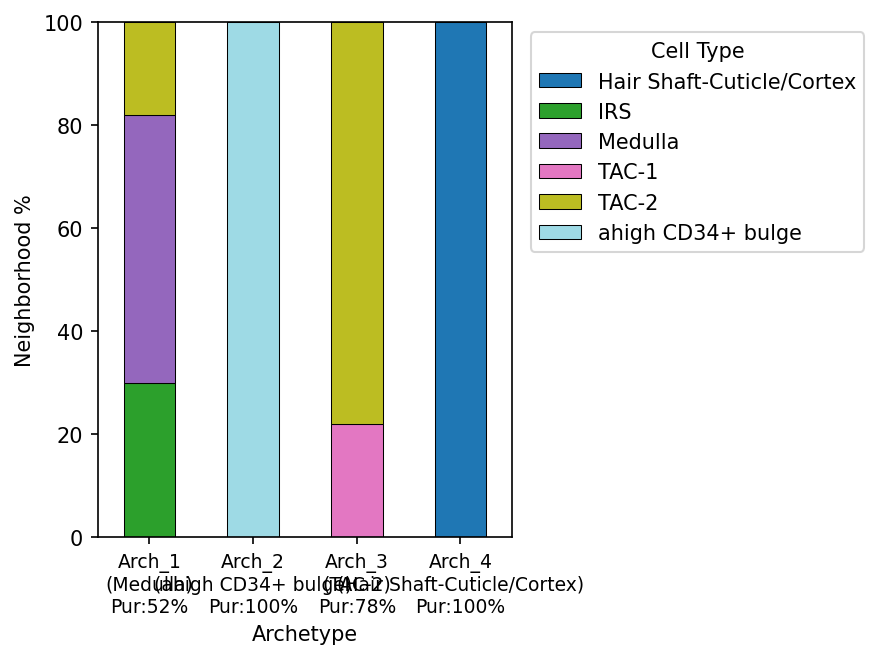

In [26]:
cell_types = rna_adata.obs['cell_type']

def select_and_refine_archetypes(Z, cell_types, D, k_neigh=50, purity_thresh=0.20, seed=0):
    N, dim = Z.shape
    cell_types = np.array(cell_types)
    c = Z.mean(axis=0)
    first = int(np.argmax(((Z - c) ** 2).sum(1)))
    fps_seeds = [first]
    dmin = ((Z - Z[first]) ** 2).sum(1)
    for _ in range(D - 1):
        nxt = int(np.argmax(dmin)); fps_seeds.append(nxt)
        dmin = np.minimum(dmin, ((Z - Z[nxt]) ** 2).sum(1))

    nn = NearestNeighbors(n_neighbors=k_neigh).fit(Z)
    _, indices = nn.kneighbors(Z[fps_seeds])
    medoid_indices, stats = [], []
    for d in range(D):
        neigh_idx = indices[d]; neigh_labels = cell_types[neigh_idx]
        label_counts = pd.Series(neigh_labels).value_counts()
        majority_label = label_counts.index[0]; purity = label_counts.iloc[0] / k_neigh
        core_idx = neigh_idx[neigh_labels == majority_label] if purity >= purity_thresh else neigh_idx
        centroid = Z[core_idx].mean(axis=0)
        medoid_idx = core_idx[np.argmin(((Z[core_idx] - centroid) ** 2).sum(axis=1))]
        medoid_indices.append(medoid_idx)
        stats.append({'Archetype': f"Arch_{d+1}", 'Medoid_Idx': medoid_idx,
                      'Majority_Type': majority_label, 'Purity': purity,
                      'Total_Cells': k_neigh, 'Counts': label_counts.to_dict()})
    return np.array(medoid_indices, dtype=int), stats


def geometric_soft_targets(Z, arch_idx, tau_scale=0.5):
    A = Z[arch_idx]
    d2 = ((Z[:, None, :] - A[None, :, :]) ** 2).sum(-1)
    tau = np.median(d2) * tau_scale + 1e-8
    q = np.exp(-d2 / tau)
    return (q / (q.sum(1, keepdims=True) + 1e-8)).astype(np.float32)


def plot_archetype_composition(stats, k_neigh, save_path=None):
    df_list = []
    for s in stats:
        for ctype, count in s['Counts'].items():
            df_list.append({'Archetype': f"{s['Archetype']}\n({s['Majority_Type']})\nPur:{s['Purity']:.0%}",
                            'Cell Type': ctype, 'Percentage': count / k_neigh * 100})
    pivot = pd.DataFrame(df_list).pivot(index='Archetype', columns='Cell Type',
                                        values='Percentage').fillna(0)
    fig, ax = plt.subplots(figsize=(max(6, len(stats) * 1.2), 4.5), dpi=150)
    pivot.plot(kind='bar', stacked=True, ax=ax, colormap='tab20', edgecolor='black', linewidth=0.5)
    ax.set_ylabel("Neighborhood %"); ax.set_ylim(0, 100); plt.xticks(rotation=0, fontsize=9)
    ax.legend(title="Cell Type", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
    plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


K_NEIGHBORS, PURITY_THRESH = 50, 0.20
arch_idx, arch_stats = select_and_refine_archetypes(
    Z_dec, cell_types, D=D_ATOMS, k_neigh=K_NEIGHBORS, purity_thresh=PURITY_THRESH, seed=0)
q_target = geometric_soft_targets(Z_dec, arch_idx, tau_scale=GEO_TAU_SCALE)

print("=== Archetype Evaluation Summary ===")
for s in arch_stats:
    status = "VALID" if s['Purity'] >= PURITY_THRESH else "WARNING: MIXED"
    print(f"[{status}] {s['Archetype']} | Medoid {s['Medoid_Idx']} | "
          f"{s['Majority_Type']} ({s['Purity']:.1%} pure, n={K_NEIGHBORS})")
_ent = -(q_target * np.log(q_target + 1e-8)).sum(1).mean()
print(f"Soft-target entropy: {_ent:.3f} / {np.log(D_ATOMS):.3f} max")
plot_archetype_composition(arch_stats, K_NEIGHBORS, save_path=f"{OUT_DIR}/archetype_composition.png")

## Step 7: GRN dictionary model (shared base + residual atoms)

`predict_rna = A_base @ tf + Σ_d w_d (A_d @ tf)`. Unchanged from the unpaired model.

In [27]:
def init_atoms_from_soft_targets(X, q, M, A_tfs):
    D, G = q.shape[1], X.shape[1]
    W_init = np.zeros((D, G, len(A_tfs)), dtype=np.float32)
    for d in range(D):
        w = q[:, d]; wsum = w.sum() + 1e-8
        mean_in  = (X * w[:, None]).sum(0) / wsum
        mean_out = (X * (1 - w)[:, None]).sum(0) / ((1 - w).sum() + 1e-8)
        lfc = np.log1p(mean_in) - np.log1p(mean_out)
        for t_i in range(len(A_tfs)):
            col = M[:, t_i]
            if col.sum() == 0: continue
            lfc_masked = lfc * col
            rng = np.abs(lfc_masked).max() + 1e-8
            W_init[d, :, t_i] = lfc_masked / rng * 0.3
    return W_init


class GRNDictionary(nn.Module):
    def __init__(self, G, T, M, D=4):
        super().__init__()
        self.D, self.G, self.T = D, G, T
        self.W_raw  = nn.Parameter(torch.zeros(D, G, T))
        self.W_base = nn.Parameter(torch.zeros(G, T))
        self.register_buffer("M", torch.tensor(M, dtype=torch.float32))
        self.register_buffer("TF_access", torch.zeros(T))
        self.register_buffer("mean_tf",  torch.zeros(T))

    def init_from_atoms(self, W_init):
        with torch.no_grad():
            self.W_raw.copy_(torch.tensor(np.arctanh(np.clip(W_init, -0.95, 0.95)), dtype=torch.float32))
        print("GRN atoms initialized from archetype soft-LFC profiles (base starts at 0).")

    @property
    def A_dict(self):
        return torch.tanh(self.W_raw) * self.M.unsqueeze(0)

    @property
    def A_base(self):
        return torch.tanh(self.W_base) * self.M

    def _atom_term(self, X_in, weights):
        P = torch.einsum('bt,dgt->dbg', X_in, self.A_dict)
        return (P * weights.T.unsqueeze(-1)).sum(0)

    def predict_rna(self, X_TF, weights):
        return (X_TF @ self.A_base.T) + self._atom_term(X_TF, weights)

    def production_from_lead(self, tf_lead, weights):
        return (tf_lead @ self.A_base.T) + self._atom_term(tf_lead, weights)

    def effective_A(self, weights_vec):
        return self.A_base + torch.einsum('d,dgt->gt', weights_vec, self.A_dict)

    def sparsity_loss(self):
        return torch.abs(self.A_dict).mean() + torch.abs(self.A_base).mean()

    def diversity_loss(self):
        A_flat = self.A_dict.reshape(self.D, -1)
        A_norm = F.normalize(A_flat, dim=1)
        eye = torch.eye(self.D, device=A_flat.device)
        param_div = ((A_norm @ A_norm.T) * (1 - eye)).abs().mean()
        pred = torch.einsum('dgt,t->dg', self.A_dict, self.mean_tf)
        pred = F.normalize(pred, dim=1)
        pred_div = ((pred @ pred.T) * (1 - eye)).abs().mean()
        return 0.5 * param_div + 0.5 * pred_div

    def tf_access_consistency_loss(self):
        closed = 1.0 - self.TF_access.clamp(0, 1)
        return (torch.abs(self.A_dict) * closed.unsqueeze(0).unsqueeze(0)).mean()


class CellStateEncoder(nn.Module):
    """RNA -> D mixing weights. Warm-started to reproduce the soft targets q."""
    def __init__(self, G, D, hidden=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(G, hidden), nn.LayerNorm(hidden), nn.GELU(),
            nn.Linear(hidden, hidden // 2), nn.GELU(),
        )
        self.head = nn.Linear(hidden // 2, D)
        self.D = D

    def init_from_soft_targets(self, X, q, n_epochs=40, lr=1e-3, batch=256):
        print("Pre-training encoder to match geometric soft targets...")
        self.train()
        opt = torch.optim.Adam(self.parameters(), lr=lr)
        X_t = torch.tensor(X, dtype=torch.float32); q_t = torch.tensor(q, dtype=torch.float32)
        dl  = DataLoader(TensorDataset(X_t, q_t), batch_size=batch, shuffle=True)
        for ep in range(n_epochs):
            tot = 0.0
            for xb, qb in dl:
                logp = F.log_softmax(self.head(self.encoder(xb)), dim=-1)
                loss = (qb * (torch.log(qb + 1e-8) - logp)).sum(1).mean()
                opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item()
            if ep % 10 == 0:
                print(f"  encoder pretrain epoch {ep}: KL={tot/len(dl):.4f}")
        print("Encoder pretraining complete.")

    def forward(self, rna, temperature=1.0):
        logits = self.head(self.encoder(rna))
        return F.softmax(logits / temperature, dim=-1)

## Step 8: Linear decoder (interpretable 2D embedding)

In [28]:
class LinearDecoder(nn.Module):
    def __init__(self, hidden, G, ld_dim=2):
        super().__init__()
        self.bottleneck = nn.Linear(hidden, ld_dim)
        self.W_dec = nn.Linear(ld_dim, G, bias=True)
        nn.init.normal_(self.W_dec.weight, std=0.01); nn.init.zeros_(self.W_dec.bias)
        nn.init.orthogonal_(self.bottleneck.weight);  nn.init.zeros_(self.bottleneck.bias)

    def forward(self, h):
        z = self.bottleneck(h)
        return z, self.W_dec(z)

    def reconstruction_loss(self, h, x):
        _, xh = self.forward(h)
        return F.mse_loss(xh, x)

    def ld_regularization_loss(self, h):
        z, _ = self.forward(h)
        zc = z - z.mean(0)
        var_loss = -torch.log((zc ** 2).mean(0) + 1e-4).mean()
        cov = (zc.T @ zc) / zc.shape[0]
        orth_loss = cov[0, 1].pow(2) + cov[1, 0].pow(2)
        return var_loss + orth_loss

    def get_gene_loadings(self):
        return self.W_dec.weight.detach().cpu().numpy()


def plot_ld_embedding(z_2d_rna, pseudo_norm, gene_loadings, A_genes,
                      z_2d_atac=None, highlight_genes=None, n_arrow_genes=15, save_path=None):
    has_atac = z_2d_atac is not None
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=150)

    ax = axes[0]
    if has_atac:
        ax.scatter(z_2d_atac[:, 0], z_2d_atac[:, 1], c='lightgray', s=6, alpha=0.4,
                   edgecolors='none', label='ATAC', rasterized=True)
    scv = ax.scatter(z_2d_rna[:, 0], z_2d_rna[:, 1], c=pseudo_norm, cmap='viridis',
                     s=10, alpha=0.7, edgecolors='none', rasterized=True)
    plt.colorbar(scv, ax=ax, fraction=0.04, label='pseudotime proxy')
    ax.set_title('LD-VAE (RNA)', fontsize=10); ax.set_xlabel('LD 1'); ax.set_ylabel('LD 2')

    ax = axes[1]
    ax.scatter(z_2d_rna[:, 0], z_2d_rna[:, 1], c='#2166ac', s=8, alpha=0.6,
               edgecolors='none', label=f'RNA (n={len(z_2d_rna)})', rasterized=True)
    if has_atac:
        ax.scatter(z_2d_atac[:, 0], z_2d_atac[:, 1], c='#d73027', s=8, alpha=0.6,
                   edgecolors='none', label=f'ATAC (n={len(z_2d_atac)})', rasterized=True)
    ax.set_title('LD-VAE (by modality)', fontsize=10); ax.legend(fontsize=8, frameon=False)
    ax.set_xlabel('LD 1'); ax.set_ylabel('LD 2')

    ax = axes[2]
    ax.scatter(z_2d_rna[:, 0], z_2d_rna[:, 1], c='lightgray', s=4, alpha=0.3,
               edgecolors='none', rasterized=True)
    mags = np.linalg.norm(gene_loadings, axis=1)
    if highlight_genes is not None:
        hi = [i for i, g in enumerate(A_genes) if g in highlight_genes]
        other = [i for i in np.argsort(-mags) if i not in hi]
        show = hi + other[:max(0, n_arrow_genes - len(hi))]
    else:
        show = np.argsort(-mags)[:n_arrow_genes]
    xr = np.ptp(z_2d_rna[:, 0]); yr = np.ptp(z_2d_rna[:, 1])
    scale = 0.35 * min(xr, yr) / (mags[show].max() + 1e-8)
    for idx in show:
        dx, dy = gene_loadings[idx] * scale
        col = '#d73027' if (highlight_genes and A_genes[idx] in highlight_genes) else '#2166ac'
        ax.annotate('', xy=(dx, dy), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color=col, lw=1.5))
        ax.text(dx * 1.08, dy * 1.08, A_genes[idx], fontsize=7, color=col, ha='center', va='center')
    ax.set_title('Gene loadings biplot', fontsize=10); ax.set_xlabel('LD 1'); ax.set_ylabel('LD 2')

    for a in axes:
        a.spines['top'].set_visible(False); a.spines['right'].set_visible(False)
    plt.tight_layout()
    if save_path: plt.savefig(save_path, bbox_inches='tight', dpi=150)
    plt.show()

## Step 9: BERT-style masked reconstruction

In [29]:
def masked_reconstruction_loss(grn, mix_weights, rna_batch, tf_batch, tf_indices_in_G, mask_frac=0.40):
    B, Gg = rna_batch.shape
    device = rna_batch.device
    mask = torch.rand(B, Gg, device=device) < mask_frac
    tf_input_masked = tf_batch.clone()
    batch_idx = torch.arange(B, device=device).unsqueeze(1)
    tf_input_masked[batch_idx, torch.arange(len(tf_indices_in_G), device=device)] *= \
        (~mask[batch_idx, tf_indices_in_G]).float()
    rna_pred = grn.predict_rna(tf_input_masked, mix_weights)
    if mask.sum() == 0:
        return rna_pred.mean() * 0.0
    return F.mse_loss(rna_pred[mask], rna_batch[mask])


tf_indices_in_G = torch.tensor([sub_g2i.get(tf, -1) for tf in A_tfs], dtype=torch.long)
assert (tf_indices_in_G >= 0).all(), "some TF not found in A_genes"

## Step 10: Velocity head (ATAC→RNA lead), losses

In [30]:
class DictVelocityHead(nn.Module):
    """Per-gene kinetic gain. Diagonal by construction: calibrates response speed, cannot
    rotate the disequilibrium. The arrow of time comes from the lead, not a learned rotation."""
    def __init__(self, G, hidden=None):
        super().__init__()
        self.log_rate = nn.Parameter(torch.zeros(G))
        self.scale = nn.Parameter(torch.ones(1))

    def forward(self, rna, disequil):
        return disequil * F.softplus(self.log_rate) * self.scale


def velocity_consistency_loss(velocity, disequil):
    v = F.normalize(velocity, dim=1); d = F.normalize(disequil, dim=1)
    cos = (v * d).sum(1)
    mag = torch.abs(velocity.norm(dim=1) - disequil.norm(dim=1).detach()).mean()
    return (1.0 - cos).mean() + 0.1 * mag


def atac_direction_loss(velocity, gene_access_batch):
    closed = 1.0 - gene_access_batch.to(velocity.device)
    return (closed * torch.relu(velocity)).mean()

## Step 11: Neighbor index + per-cell lead (PAIRED — no matching)

The only substantive change from the unpaired model: `local_access` is the cell's **own**
kNN-smoothed gene activity, not a matched estimate. `build_local_atac` is gone. The lead
math below is untouched.

In [31]:
def build_neighbor_index(X, V_dec2, Z_dec, mode="latent", k=15):
    if mode == "decipher":   ref = V_dec2
    elif mode == "pca":      ref = PCA(n_components=min(50, X.shape[1] - 1), random_state=42).fit_transform(X)
    elif mode == "latent":   ref = Z_dec
    else: raise ValueError(mode)
    _, ni = NearestNeighbors(n_neighbors=k).fit(ref).kneighbors(ref)
    return torch.tensor(ni, dtype=torch.long)


def knn_smooth(signal, neighbor_idx, k=10, chunk=512):
    """First-moment (kNN mean) of a per-cell, per-gene SCALAR signal. Safe on a scalar
    feature: no direction to cancel, so it denoises without erasing a bifurcation."""
    nb = np.asarray(neighbor_idx)[:, :k]
    out = np.empty_like(np.asarray(signal, dtype=np.float32))
    for s in range(0, nb.shape[0], chunk):
        e = min(s + chunk, nb.shape[0])
        out[s:e] = signal[nb[s:e]].mean(axis=1)
    return out


neighbor_indices_t = build_neighbor_index(X, V_dec2, Z_dec, mode=NEIGHBOR_SPACE, k=15)
_nb = neighbor_indices_t.numpy()

# ── PAIRED: each cell's own ATAC gene activity is the accessibility signal ─────
# (unpaired code ran build_local_atac here to fabricate a matched estimate; deleted.)
local_access = gene_activity.copy()

# ── FIRST MOMENTS: smooth BOTH modalities at the SAME neighborhood scale ───────
local_access = knn_smooth(local_access, _nb, k=K_MOMENT)
X_smooth     = knn_smooth(X,            _nb, k=K_MOMENT)

atac_z = zscore_cols(local_access)     # (N, G)
rna_z  = zscore_cols(X_smooth)         # (N, G)

# ── lead = balanced accessibility-minus-expression (the arrow of time) ────────
# both terms are unit-variance z-scores, so the plain difference is amplitude-matched and
# contraction-free. With real pairing, per-gene rho should now be clearly > 0 (unlike the
# unpaired ~0), which is the whole point of this run.
rho  = (atac_z * rna_z).mean(0)                       # (G,) per-gene concordance
lead = (atac_z - rna_z).astype(np.float32)           # (N, G)
lead = knn_smooth(lead, _nb, k=K_MOMENT)

atac_z_t = torch.tensor(atac_z, dtype=torch.float32)
rna_z_t  = torch.tensor(rna_z,  dtype=torch.float32)
lead_t   = torch.tensor(lead,   dtype=torch.float32)
print(f"Lead ready (paired). mean rho={rho.mean():+.3f} | median rho={np.median(rho):+.3f} | "
      f"lead RMS={np.sqrt((lead ** 2).mean()):.4f}")
print("  (unpaired baseline was rho≈0.04; higher here = pairing carries real chromatin lead)")

Lead ready (paired). mean rho=+0.029 | median rho=+0.008 | lead RMS=0.8315
  (unpaired baseline was rho≈0.04; higher here = pairing carries real chromatin lead)


## Step 12: 2D velocity projection (drift-corrected, magnitude-preserving)

In [32]:
def project_to_2d(V_pred_full, X_2d_vis, X_full, search_space=None, k=30, scale=1.0,
                   drift_correct=True, density_k=15, adaptive_scale=False):
    if search_space is None:
        search_space = X_2d_vis
    N = V_pred_full.shape[0]
    _, idx = NearestNeighbors(n_neighbors=k).fit(search_space).kneighbors(search_space)
    d_high = X_full[idx] - X_full[:, None, :]
    d_low  = X_2d_vis[idx] - X_2d_vis[:, None, :]
    v_norm = np.linalg.norm(V_pred_full, axis=1, keepdims=True) + 1e-8
    d_norm = np.linalg.norm(d_high, axis=2) + 1e-8
    sims   = np.einsum('ng,nkg->nk', V_pred_full, d_high) / (d_norm * v_norm)
    sims   = sims - sims.mean(axis=1, keepdims=True)
    if adaptive_scale:
        dd, _ = NearestNeighbors(n_neighbors=density_k).fit(X_2d_vis).kneighbors(X_2d_vis)
        dens = 1.0 / (dd[:, 1:].mean(1) + 1e-8)
        dens = 1.0 + 2.0 * (dens - dens.min()) / (np.ptp(dens) + 1e-8)
    else:
        dens = np.ones(N, dtype=np.float32)
    w = np.exp(sims * (scale * dens)[:, None])
    w = w / (w.sum(1, keepdims=True) + 1e-8)
    d_low_unit = d_low / (np.linalg.norm(d_low, axis=2, keepdims=True) + 1e-8)
    if drift_correct:
        w = w - 1.0 / k
    V_emb2 = np.einsum('nk,nkd->nd', w, d_low_unit).astype(np.float32)
    speed = np.linalg.norm(V_pred_full, axis=1)
    speed = speed / (np.percentile(speed, 95) + 1e-8)
    V_emb2 *= speed[:, None]
    V_emb2[np.linalg.norm(V_pred_full, axis=1) < 1e-8] = 0.0
    return V_emb2

## Step 13: Streamplot helper + training GIF maker

In [41]:
import io
from PIL import Image
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree


import numpy as np
from sklearn.neighbors import NearestNeighbors
from scipy.spatial import cKDTree
from scipy.ndimage import gaussian_filter

def draw_stream(ax, X_emb, V_emb, grid_n=120, thr_pct=45, density=1.4, smooth=1.2):
    """scVelo-style stream from per-cell 2D vectors on an embedding. Density-only mask."""
    x_min, x_max = X_emb[:, 0].min(), X_emb[:, 0].max()
    y_min, y_max = X_emb[:, 1].min(), X_emb[:, 1].max()
    
    # 1. Define dx and dy for padding (e.g., 5% padding)
    dx = (x_max - x_min) * 0.05
    dy = (y_max - y_min) * 0.05
    
    def make_uniform_line(lo, hi, n):
        step = (hi - lo) / (n - 1)
        return lo + step * np.arange(n)
    
    x_line = make_uniform_line(x_min - dx, x_max + dx, grid_n)
    y_line = make_uniform_line(y_min - dy, y_max + dy, grid_n)
    
    # 2. FIX: Create a 2D meshgrid to properly evaluate all grid intersections
    Xg, Yg = np.meshgrid(x_line, y_line)
    
    # sanity check before moving on
    assert np.allclose(np.diff(x_line), x_line[1] - x_line[0])
    assert np.allclose(np.diff(y_line), y_line[1] - y_line[0])
    
    # gp is now a flattened list of all (grid_n * grid_n) coordinates
    gp = np.c_[Xg.ravel(), Yg.ravel()]
    
    sub = np.random.choice(len(X_emb), min(3000, len(X_emb)), replace=False)
    _, gi = NearestNeighbors(n_neighbors=20).fit(X_emb[sub]).kneighbors(gp)
    Vg = V_emb[sub][gi].mean(1)
    
    dgrid = NearestNeighbors(n_neighbors=1).fit(X_emb).kneighbors(gp)[0].ravel()
    thr = np.percentile(dgrid, thr_pct)
    mask = dgrid < thr
    
    if mask.sum() == 0: 
        mask = np.ones(len(gp), dtype=bool)
        
    _, nn = cKDTree(gp[mask]).query(gp, k=1)
    
    # Reshape correctly uses the 2D shape from the meshgrid
    U = Vg[mask][nn, 0].reshape(Xg.shape)
    W = Vg[mask][nn, 1].reshape(Yg.shape)
    
    gm = dgrid < thr
    Uf, Wf = U.ravel(), W.ravel()
    
    # Zero out empty areas before applying the gaussian blur
    Uf[~gm] = 0
    Wf[~gm] = 0
    
    U = gaussian_filter(Uf.reshape(Xg.shape), smooth)
    W = gaussian_filter(Wf.reshape(Yg.shape), smooth)
    
    # 3. Apply np.nan to empty regions AFTER the gaussian filter.
    # This instructs streamplot to entirely ignore these areas instead of plotting zeros.
    U[~(gm.reshape(Xg.shape))] = np.nan
    W[~(gm.reshape(Yg.shape))] = np.nan
    
    # Pass the strict 1D x_line and y_line to prevent the spacing errors
    ax.streamplot(x_line, y_line, U, W, color="black", density=density, linewidth=1, arrowsize=1,
                  arrowstyle='-|>', minlength=0.2, integration_direction='both', zorder=3)


class VelocityGIFMaker:
    def __init__(self, dpi=150):
        self.dpi, self.frames = dpi, []

    def _render(self, X_2d, V_2d, color, epoch):
        fig, ax = plt.subplots(figsize=(4, 3.5), dpi=self.dpi)
        scv = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=color, cmap="viridis", s=20, alpha=0.6,
                         edgecolors='none', rasterized=True)
        draw_stream(ax, X_2d, V_2d, density=1.2)
        ax.set_title(f"Velocity @ epoch {epoch}", fontsize=11, fontweight='bold')
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        plt.colorbar(scv, ax=ax, fraction=0.04, pad=0.04).set_label("pseudotime proxy")
        plt.tight_layout()
        buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=self.dpi, bbox_inches='tight')
        plt.close(fig); buf.seek(0)
        return Image.open(buf).copy()

    def add_frame(self, X_2d, V_2d, color, epoch):
        self.frames.append(self._render(X_2d, V_2d, color, epoch))

    def save(self, path, fps=3):
        if not self.frames: return
        self.frames[0].save(path, save_all=True, append_images=self.frames[1:],
                            loop=0, duration=int(1000 / fps))
        print(f"Saved GIF: {path}")

    def save_slide_png(self, path):
        if not self.frames: return
        w, h = self.frames[-1].size
        self.frames[-1].resize((w * 2, h * 2), Image.LANCZOS).save(path, dpi=(300, 300))

## Step 14: Training loop

Phase 1 = GRN + encoder warmup. Phase 2 adds the ATAC-led velocity. Temperature fixed at 1.0.
Identical to the unpaired model; only the `lead_t` it consumes is now paired.

In [37]:
W1 = dict(MASK=2.0, SPARSE=5e-3, ACCESS=0.1, DIVERSE=10.0, ANCHOR=1.0, LD=0.5, LD_REG=0.1)
W2 = dict(MASK=1.0, SPARSE=5e-3, ACCESS=0.1, DIVERSE=5.0, ANCHOR=0.5,
          VEL=3.0, ATAC=1.0, LD=0.3, LD_REG=0.05)
PLOT_EVERY = 10

G, T = X.shape[1], X_TF.shape[1]
X_t     = torch.tensor(X,    dtype=torch.float32)
X_TF_t  = torch.tensor(X_TF, dtype=torch.float32)
q_t     = torch.tensor(q_target, dtype=torch.float32)
cell_idx_t = torch.arange(X_t.size(0))

dataset = TensorDataset(X_t, X_TF_t, cell_idx_t)
loader  = DataLoader(dataset, batch_size=BATCH_SIZE,
                     sampler=RandomSampler(dataset, replacement=False), drop_last=True)

for run_i in range(NUM_RUNS):
    run_dir = OUT_DIR if (NUM_RUNS == 1) else os.path.join(OUT_DIR, f"run{run_i}")
    if os.path.exists(os.path.join(run_dir, "V_pred.npy")):
        print(f"::: Run {run_i} exists — skipping :::"); continue
    print(f"\n::: Run {run_i} :::")

    grn = GRNDictionary(G=G, T=T, M=M, D=D_ATOMS)
    grn.TF_access = TF_access_t.clone()
    grn.mean_tf   = torch.tensor(X_TF.mean(0), dtype=torch.float32)
    grn.init_from_atoms(init_atoms_from_soft_targets(X, q_target, M, A_tfs))

    cell_encoder = CellStateEncoder(G=G, D=D_ATOMS)
    cell_encoder.init_from_soft_targets(X, q_target, n_epochs=40)

    vel_head   = DictVelocityHead(G=G)
    ld_decoder = LinearDecoder(hidden=64, G=G, ld_dim=2)

    opt_grn = torch.optim.AdamW(
        list(grn.parameters()) + list(cell_encoder.parameters()) + list(ld_decoder.parameters()), lr=5e-4)
    opt_vel = torch.optim.AdamW(vel_head.parameters(), lr=2e-4)
    sch_grn = torch.optim.lr_scheduler.CosineAnnealingLR(opt_grn, T_max=N_EPOCHS, eta_min=1e-5)
    sch_vel = torch.optim.lr_scheduler.CosineAnnealingLR(opt_vel, T_max=N_EPOCHS - PHASE1_EPOCHS, eta_min=1e-5)

    gif_maker = VelocityGIFMaker(); loss_history = []

    for epoch in range(N_EPOCHS):
        phase = 1 if epoch < PHASE1_EPOCHS else 2
        if epoch == PHASE1_EPOCHS: print("── Phase 2 (joint) ──")
        anchor_scale = max(0.2, 1.0 - 0.8 * epoch / N_EPOCHS)

        grn.train(); cell_encoder.train(); vel_head.train(phase == 2)
        for p in vel_head.parameters(): p.requires_grad_(phase == 2)

        epoch_losses = []
        for rna_b, tf_b, bidx in loader:
            mix = cell_encoder(rna_b, temperature=1.0)
            l_mask    = masked_reconstruction_loss(grn, mix, rna_b, tf_b,
                                                   tf_indices_in_G.to(rna_b.device), 0.40)
            l_sparse  = grn.sparsity_loss()
            l_access  = grn.tf_access_consistency_loss()
            l_diverse = grn.diversity_loss()
            q_b       = q_t[bidx]
            l_anchor  = (q_b * (torch.log(q_b + 1e-8) - torch.log(mix + 1e-8))).sum(1).mean()
            h_b      = cell_encoder.encoder(rna_b)
            l_ld     = ld_decoder.reconstruction_loss(h_b, rna_b)
            l_ld_reg = ld_decoder.ld_regularization_loss(h_b)

            if phase == 1:
                loss_grn = (W1['MASK'] * l_mask + W1['SPARSE'] * l_sparse +
                            W1['ACCESS'] * l_access + W1['DIVERSE'] * l_diverse +
                            W1['ANCHOR'] * anchor_scale * l_anchor +
                            W1['LD'] * l_ld + W1['LD_REG'] * l_ld_reg)
                opt_grn.zero_grad(); loss_grn.backward()
                torch.nn.utils.clip_grad_norm_(
                    list(grn.parameters()) + list(cell_encoder.parameters()) +
                    list(ld_decoder.parameters()), 1.0)
                opt_grn.step()
                epoch_losses.append(float(loss_grn.item()))
            else:
                # velocity = GRN's response to the TF-level ATAC->RNA lead ONLY.
                tf_lead  = lead_t[bidx][:, tf_indices_in_G]                 # (B, T)
                disequil = grn.production_from_lead(tf_lead, mix.detach())  # (B, G)
                velocity = vel_head(rna_b, disequil)
                l_vel    = velocity_consistency_loss(velocity, disequil.detach())
                ga_b     = gene_access_t if gene_access_t.dim() == 1 else gene_access_t[bidx]
                l_atac   = atac_direction_loss(velocity, ga_b)
                loss_vel = W2['VEL'] * l_vel + W2['ATAC'] * l_atac
                loss_grn = (W2['MASK'] * l_mask + W2['SPARSE'] * l_sparse +
                            W2['ACCESS'] * l_access + W2['DIVERSE'] * l_diverse +
                            W2['ANCHOR'] * anchor_scale * l_anchor +
                            W2['LD'] * l_ld + W2['LD_REG'] * l_ld_reg)
                opt_grn.zero_grad(); opt_vel.zero_grad()
                loss_grn.backward(retain_graph=True); loss_vel.backward()
                torch.nn.utils.clip_grad_norm_(
                    list(grn.parameters()) + list(cell_encoder.parameters()) +
                    list(ld_decoder.parameters()), 1.0)
                torch.nn.utils.clip_grad_norm_(vel_head.parameters(), 1.0)
                opt_grn.step(); opt_vel.step()
                epoch_losses.append(float((loss_grn + loss_vel).item()))

        sch_grn.step()
        if phase == 2: sch_vel.step()

        if epoch % 20 == 0 or epoch == N_EPOCHS - 1:
            avg = float(np.mean(epoch_losses)); loss_history.append(avg)
            print(f"  [P{phase}] epoch {epoch:03d}  loss={avg:.4f}  anchor_scale={anchor_scale:.2f}")

        # if epoch % PLOT_EVERY == 0 or epoch == N_EPOCHS - 1:
        #     grn.eval(); vel_head.eval(); cell_encoder.eval()
        #     with torch.no_grad():
        #         mw = cell_encoder(X_t, temperature=1.0)
        #         dis = grn.production_from_lead(lead_t[:, tf_indices_in_G], mw)
        #         V_snap = vel_head(X_t, dis).numpy()
        #     V_snap_2d = project_to_2d(V_snap, V_dec2, rna_z, search_space=Z_dec, k=15, scale=1.0)
        #     gif_maker.add_frame(V_dec2, V_snap_2d, pseudo_norm, epoch)
        #     grn.train(); vel_head.train(); cell_encoder.train()

    # ── save ──────────────────────────────────────────────────────────────────
    grn.eval(); vel_head.eval(); cell_encoder.eval()
    with torch.no_grad():
        mix_full = cell_encoder(X_t, temperature=1.0)
        disequil_full = grn.production_from_lead(lead_t[:, tf_indices_in_G], mix_full)
        V_pred   = vel_head(X_t, disequil_full).cpu().numpy()
        steady_full = grn.predict_rna(X_TF_t, mix_full).cpu().numpy()
        A_dict_np = grn.A_dict.cpu().numpy(); A_base_np = grn.A_base.cpu().numpy()
        A_learned = grn.effective_A(mix_full.mean(0)).cpu().numpy()
        all_mix_weights = mix_full.cpu().numpy()
        z_2d_np = ld_decoder.forward(cell_encoder.encoder(X_t))[0].cpu().numpy()
        gene_loadings = ld_decoder.get_gene_loadings()

    os.makedirs(run_dir, exist_ok=True)
    for d in ([run_dir] + ([OUT_DIR] if (NUM_RUNS > 1 and run_i == 0) else [])):
        os.makedirs(d, exist_ok=True)
        np.save(f"{d}/V_pred.npy", V_pred)
        np.save(f"{d}/A_dict.npy", A_dict_np); np.save(f"{d}/A_base.npy", A_base_np)
        np.save(f"{d}/A_learned.npy", A_learned); np.save(f"{d}/mix_weights.npy", all_mix_weights)
        np.save(f"{d}/steady_state.npy", steady_full)
        np.save(f"{d}/A_genes.npy", A_genes); np.save(f"{d}/A_tfs.npy", A_tfs)
        np.save(f"{d}/gene_idx.npy", gene_idx); np.save(f"{d}/tf_idx.npy", tf_idx)
        np.save(f"{d}/z_ld_2d.npy", z_2d_np); np.save(f"{d}/gene_loadings.npy", gene_loadings)
        np.save(f"{d}/loss_history.npy", np.array(loss_history))
        np.save(f"{d}/lead.npy", lead); np.save(f"{d}/rho.npy", rho)
        gif_maker.save(f"{d}/velocity_training.gif", fps=3)
        gif_maker.save_slide_png(f"{d}/velocity_slide_final.png")
    print(f"Run {run_i} saved to {run_dir}")

print("Training complete.")


::: Run 0 :::
GRN atoms initialized from archetype soft-LFC profiles (base starts at 0).
Pre-training encoder to match geometric soft targets...
  encoder pretrain epoch 0: KL=0.1912
  encoder pretrain epoch 10: KL=0.0025
  encoder pretrain epoch 20: KL=0.0012
  encoder pretrain epoch 30: KL=0.0007
Encoder pretraining complete.
  [P1] epoch 000  loss=4.9766  anchor_scale=1.00
  [P1] epoch 020  loss=0.5506  anchor_scale=0.87
── Phase 2 (joint) ──
  [P2] epoch 040  loss=2.8552  anchor_scale=0.73
  [P2] epoch 060  loss=28.6598  anchor_scale=0.60
  [P2] epoch 080  loss=35.9149  anchor_scale=0.47
  [P2] epoch 100  loss=38.2610  anchor_scale=0.33
  [P2] epoch 119  loss=38.6047  anchor_scale=0.21
Run 0 saved to bert_grn_out_paired_run1
Training complete.


## Step 15: LD-VAE biplot (RNA + ATAC)

In [ ]:
grn.eval(); vel_head.eval(); cell_encoder.eval()
with torch.no_grad():
    z_rna  = ld_decoder(cell_encoder.encoder(X_t))[0].cpu().numpy()
    z_atac = ld_decoder(cell_encoder.encoder(torch.tensor(gene_activity, dtype=torch.float32)))[0].cpu().numpy()
    scaler = StandardScaler()
    z_rna_plot  = scaler.fit_transform(z_rna)
    z_atac_plot = scaler.transform(z_atac)
    gl = ld_decoder.get_gene_loadings()
    gl_plot = gl * (2.0 / (np.abs(gl).max() + 1e-8))

plot_ld_embedding(z_rna_plot, pseudo_norm, gl_plot, A_genes,
                  z_2d_atac=z_atac_plot, highlight_genes=MARKER_GENES,
                  save_path=f"{OUT_DIR}/ld_embedding_biplot.png")
print(f"RNA z std/dim:  {z_rna.std(0).round(3)} | ATAC z std/dim: {z_atac.std(0).round(3)}")

## Step 16: The trajectory — scVelo-style stream plot

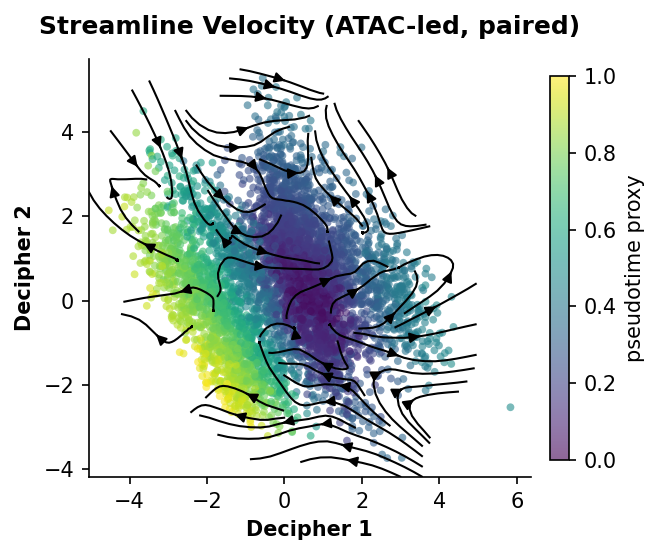

In [42]:
V_pred   = np.load(f"{OUT_DIR}/V_pred.npy")
V_smooth = project_to_2d(V_pred, V_dec2, rna_z, search_space=Z_dec, k=45, scale=0.4, drift_correct=True)

# (A) colored by pseudotime proxy
fig, ax = plt.subplots(figsize=(4.5, 3.8), dpi=150)
scv = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=pseudo_norm, cmap="viridis",
                 s=14, alpha=0.6, edgecolors='none', rasterized=True)
draw_stream(ax, V_dec2, V_smooth, thr_pct=65, density=1.4)
ax.set_xlabel("Decipher 1", fontweight='bold'); ax.set_ylabel("Decipher 2", fontweight='bold')
ax.set_title("Streamline Velocity (ATAC-led, paired)", fontsize=12, fontweight='bold', pad=12)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.colorbar(scv, ax=ax, fraction=0.04, pad=0.04).set_label("pseudotime proxy")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/velocity_stream.png", bbox_inches='tight', dpi=150)
plt.show()

In [ ]:
# (B) same field colored by cell type (the informative view for this dataset)
uniq = list(pd.Series(cell_types).value_counts().index)
cmap = plt.get_cmap('tab20', max(len(uniq), 3))
palette = {ct: cmap(i) for i, ct in enumerate(uniq)}

fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
for ct in uniq:
    m = cell_types == ct
    ax.scatter(V_dec2[m, 0], V_dec2[m, 1], c=[palette[ct]], s=12, alpha=0.75,
               label=ct, edgecolors='none', rasterized=True)
draw_stream(ax, V_dec2, V_smooth, thr_pct=65, density=1.4)
ax.set_xlabel("Decipher 1", fontweight='bold'); ax.set_ylabel("Decipher 2", fontweight='bold')
ax.set_title("Streamline Velocity by cell type (paired)", fontsize=12, fontweight='bold', pad=12)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/velocity_stream_celltypes.png", bbox_inches='tight', dpi=150)
plt.show()

## Step 16b: Projection sanity + direction diagnostics (read-only)

Confirms the 2D projection operator is faithful, and reports whether the learned field points
"forward" along the pseudotime proxy. `contraction cos` should be ~0 (no pull-to-centroid).

In [ ]:
def _cosr(A, B, e=1e-8):
    A = A / (np.linalg.norm(A, axis=1, keepdims=True) + e)
    B = B / (np.linalg.norm(B, axis=1, keepdims=True) + e)
    return (A * B).sum(1)

pt = np.asarray(pseudo_norm)
lo = pt < np.quantile(pt, 0.33); hi = pt > np.quantile(pt, 0.67); mid = ~lo & ~hi

# forward reference = local pseudotime-proxy gradient in the embedding
_, ii = NearestNeighbors(n_neighbors=15).fit(V_dec2).kneighbors(V_dec2)
dpt   = pt[ii] - pt[:, None]
fwd2d = ((V_dec2[ii] - V_dec2[:, None, :]) * np.maximum(dpt, 0.0)[:, :, None]).sum(1)

V_real_2d = project_to_2d(V_pred, V_dec2, rna_z, search_space=Z_dec, k=20, scale=1.0)
print(f"[2D] forward cos overall : {np.nanmean(_cosr(V_real_2d, fwd2d)):+.3f}   (want > 0)")
print(f"[2D]   EARLY {np.nanmean(_cosr(V_real_2d, fwd2d)[lo]):+.3f} | "
      f"MID {np.nanmean(_cosr(V_real_2d, fwd2d)[mid]):+.3f} | "
      f"LATE {np.nanmean(_cosr(V_real_2d, fwd2d)[hi]):+.3f}")
mag = np.linalg.norm(V_pred, axis=1); mag = mag / (mag.mean() + 1e-8)
print(f"|V| by tertile (want EARLY/MID > LATE): "
      f"EARLY {mag[lo].mean():.2f} | MID {mag[mid].mean():.2f} | LATE {mag[hi].mean():.2f}")
to_mean = _cosr(V_pred, -rna_z)
print(f"[contraction] cos(V, toward-mean): {to_mean.mean():+.3f}  (want ~0) | "
      f"fraction inward: {(to_mean > 0).mean():.1%}")

# projection-operator fidelity on a known-clean synthetic branch (data-independent)
_rng = np.random.default_rng(0)
def _mk_branch(nper=300):
    P, Tg = [], []
    t = np.linspace(0, 1, nper); P += list(np.c_[0*t, -1.5 + 1.5*t]); Tg += list(np.c_[0*t, np.ones_like(t)])
    for ang in (110, 90, 70):
        a = np.deg2rad(ang); t = np.linspace(0, 1, nper)
        P += list(np.c_[np.cos(a)*2*t, np.sin(a)*2*t])
        Tg += list(np.c_[np.cos(a)*np.ones_like(t), np.sin(a)*np.ones_like(t)])
    P = np.array(P) + _rng.normal(0, 0.05, (4*nper, 2)); Tg = np.array(Tg)
    return P, Tg / np.linalg.norm(Tg, axis=1, keepdims=True)
_P, _Tg = _mk_branch(); _G = 300
_W = _rng.normal(0, 1.5, (2, _G)); _bb = _rng.uniform(0, 2*np.pi, _G)
_C = np.cos(_P @ _W + _bb); _J = np.stack([_C*_W[0], _C*_W[1]], -1)
_S = np.sin(_P @ _W + _bb); _S = (_S - _S.mean(0)) / (_S.std(0) + 1e-8)
_Vhi = np.einsum('ngd,nd->ng', _J, _Tg).astype(np.float32)
_V2 = project_to_2d(_Vhi, _P, _S, search_space=_S, k=20, scale=1.0)
print(f"[PROJECTION-SYNTH] known-clean field -> forward cos = "
      f"{np.nanmean(_cosr(_V2, _Tg)):+.3f}   (near +1 => projection operator is faithful)")

## Step 17: GRN mixing diagnostics (temperature = 1.0)

In [ ]:
grn.eval(); cell_encoder.eval()
with torch.no_grad():
    W_soft = cell_encoder(X_t, temperature=1.0).numpy()
ent = -(W_soft * np.log(W_soft + 1e-8)).sum(1)
print("Mean mixing weight/atom:", W_soft.mean(0).round(3))
print(f"Mean entropy: {ent.mean():.3f} / {np.log(D_ATOMS):.3f} max | "
      f"committed (max>0.8): {(W_soft.max(1) > 0.8).mean():.1%}")

ncol = (D_ATOMS + 1) // 2
fig, axes = plt.subplots(2, ncol, figsize=(5 * ncol, 8)); axes = np.atleast_1d(axes).flatten()
for d in range(D_ATOMS):
    ax = axes[d]
    scv = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=W_soft[:, d], cmap='YlOrRd', s=8, alpha=0.8, vmin=0, vmax=1)
    plt.colorbar(scv, ax=ax, fraction=0.04)
    top_tf = A_tfs[np.abs(grn.A_dict[d].detach().cpu().numpy()).sum(0).argmax()]
    ax.set_title(f"Atom {d}  (top TF: {top_tf})", fontsize=9)
    ax.set_xlabel("Decipher 1"); ax.set_ylabel("Decipher 2")
for j in range(D_ATOMS, len(axes)): axes[j].axis('off')
plt.suptitle("Per-cell GRN mixing weights (T=1.0)", fontsize=11)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/atom_weights_spatial.png", dpi=150, bbox_inches='tight')
plt.show()

## Step 18: **Lead diagnostics across Decipher space** (the paired-vs-unpaired test)

Everything here reads the computed `lead` (raw gene-level ATAC→RNA disequilibrium) and its
GRN-propagated form (the velocity input), and lays them over the Decipher embedding. This is
the direct check of whether the bad trajectories were a matching artifact: with real pairing,
per-gene concordance should be clearly positive and the lead field should carry a coherent
arrow of time.

In [ ]:
# per-cell scalars from the lead + the GRN-propagated disequilibrium
grn.eval(); cell_encoder.eval()
with torch.no_grad():
    mix_full = cell_encoder(X_t, temperature=1.0)
    disequil_full = grn.production_from_lead(lead_t[:, tf_indices_in_G], mix_full).cpu().numpy()
lead_mag    = np.linalg.norm(lead, axis=1)               # raw gene-level lead magnitude
disequil_mag = np.linalg.norm(disequil_full, axis=1)     # GRN-routed lead magnitude (velocity input)

# projected raw-lead field (pre-GRN arrow of time)
lead_2d = project_to_2d(lead.astype(np.float32), V_dec2, rna_z, search_space=Z_dec, k=45, scale=0.4)

fig, axes = plt.subplots(2, 2, figsize=(11, 9), dpi=150)

# (A) raw lead magnitude on Decipher space
ax = axes[0, 0]
s = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=lead_mag, cmap='magma', s=10, alpha=0.85)
plt.colorbar(s, ax=ax, fraction=0.04, label='||lead||')
ax.set_title("(A) raw ATAC→RNA lead magnitude\n(high = chromatin-RNA disequilibrium)", fontsize=10)

# (B) GRN-propagated lead magnitude (what the velocity head actually sees)
ax = axes[0, 1]
s = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=disequil_mag, cmap='magma', s=10, alpha=0.85)
plt.colorbar(s, ax=ax, fraction=0.04, label='||GRN·tf_lead||')
ax.set_title("(B) GRN-routed lead magnitude\n(velocity input; sinks should be low)", fontsize=10)

# (C) projected raw-lead field (arrow of time straight from the lead, pre-GRN)
ax = axes[1, 0]
ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=pseudo_norm, cmap='viridis', s=10, alpha=0.5, edgecolors='none')
draw_stream(ax, V_dec2, lead_2d, thr_pct=65, density=1.4)
ax.set_title("(C) raw lead field, projected\n(does the lead itself point forward?)", fontsize=10)

# (D) per-gene ATAC–RNA concordance — the headline paired-vs-unpaired number
ax = axes[1, 1]
ax.hist(rho, bins=40, color='#2166AC', alpha=0.85)
ax.axvline(float(np.mean(rho)), color='red', ls='--', label=f"mean {np.mean(rho):+.3f}")
ax.axvline(0.0, color='k', lw=0.8)
ax.set_title("(D) per-gene ATAC-RNA concordance (paired)\n(unpaired baseline ≈ 0)", fontsize=10)
ax.set_xlabel("rho(atac_z, rna_z)"); ax.set_ylabel("genes"); ax.legend(fontsize=8, frameon=False)

for ax in axes.flat:
    if ax is not axes[1, 1]:
        ax.set_xlabel("Decipher 1"); ax.set_ylabel("Decipher 2")
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/lead_diagnostics.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"lead magnitude: mean={lead_mag.mean():.3f} | "
      f"disequil magnitude: mean={disequil_mag.mean():.3f}")
print(f"per-gene rho: mean={rho.mean():+.3f} | median={np.median(rho):+.3f} | "
      f">0: {(rho > 0).mean():.1%}  (unpaired was ~50%/≈0 mean)")

In [ ]:
# per-TF lead maps: top switching TFs (largest per-cell |atac_z_TF - rna_z_TF|) on Decipher space
tf_lead_gene = (atac_z - rna_z)[:, tf_indices_in_G.numpy()]        # (N, T) gene-level TF lead
tf_switch = np.abs(tf_lead_gene).mean(0)
top_tfs = np.argsort(-tf_switch)[:6]

fig, axes = plt.subplots(2, 3, figsize=(14, 8), dpi=150); axes = axes.flatten()
for ax, t in zip(axes, top_tfs):
    v = tf_lead_gene[:, t]; lim = np.percentile(np.abs(v), 98) + 1e-8
    s = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=v, cmap='coolwarm', s=8, alpha=0.85, vmin=-lim, vmax=lim)
    plt.colorbar(s, ax=ax, fraction=0.04)
    ax.set_title(f"{A_tfs[t]}  (|lead|={tf_switch[t]:.2f})\nred=chromatin ahead of RNA", fontsize=9)
    ax.set_xlabel("Decipher 1"); ax.set_ylabel("Decipher 2")
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.suptitle("Per-TF ATAC→RNA lead across Decipher space", fontsize=11)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/lead_per_tf.png", dpi=150, bbox_inches='tight')
plt.show()

## Step 19: Marker expression across Decipher space (sanity check)

In [ ]:
plot_genes = [g for g in MARKER_GENES if g in rna_adata.var_names]
if plot_genes:
    sc.pl.embedding(rna_adata, basis=DECIPHER_BASIS, color=plot_genes, cmap='Reds',
                    frameon=False, ncols=3, wspace=0.25, hspace=0.25, show=True)
else:
    print("None of MARKER_GENES present in rna_adata.var_names; edit MARKER_GENES in Config.")

# cell-type panel too
sc.pl.embedding(rna_adata, basis=DECIPHER_BASIS, color=CELLTYPE_KEY, frameon=False, show=True)

## Appendix (optional): CellOracle GRN comparison

In [ ]:
if os.path.exists(CELLORACLE_A):
    from scipy.stats import spearmanr
    co = np.load(CELLORACLE_A)
    A_ours = np.load(f"{OUT_DIR}/A_learned.npy")
    if co.shape == A_ours.T.shape: co = co.T
    if co.shape == A_ours.shape:
        per_tf = []
        for t in range(A_ours.shape[1]):
            a, b = A_ours[:, t], co[:, t]
            support = (np.abs(a) + np.abs(b)) > 0
            if support.sum() > 5:
                rho_t, _ = spearmanr(a[support], b[support]); per_tf.append(rho_t)
        per_tf = np.array([r for r in per_tf if np.isfinite(r)])
        print(f"Per-TF Spearman vs CellOracle: mean={per_tf.mean():.3f} (n={len(per_tf)})")
    else:
        print(f"Shape mismatch: ours {A_ours.shape} vs CellOracle {co.shape}; align manually.")
else:
    print(f"No CellOracle file at {CELLORACLE_A} — skipping.")